# From Public Observations to a Checked Portfolio Decision

The variance of a portfolio is a quadratic form:

$$
\sigma_p^2=w^{\mathsf T}\Sigma w,
\qquad \mathbf 1^{\mathsf T}w=1,
\qquad w_i\geq0.
$$

Here, $w$ is the vector of portfolio weights, $\Sigma$ is the return covariance matrix, $\sigma_p^2$ is portfolio variance, $\mathbf 1$ is a vector of ones, and $w_i\geq0$ requires a long-only allocation.

,Field,Value
0,Archive,49_Industry_Portfolios_daily_CSV.zip
1,Provider,Kenneth R. French Data Library
2,Return type,Daily value-weighted return
3,Study start,2019-01-02
4,Study end,2025-12-31
5,Complete observations,1760
6,Selected industries,16
7,Selection rule,First sixteen industries in archive order
8,File SHA256,8F394FE34BEA54D41B9AAFED410425EE8F8E252EDE3C71...


,Period,Start date,End date,Observations,Use
0,Training,2019-01-02,2021-12-31,757,Estimate candidates
1,Validation,2022-01-03,2023-12-29,501,Choose one method
2,Final test,2024-01-02,2025-12-31,502,Evaluate frozen method


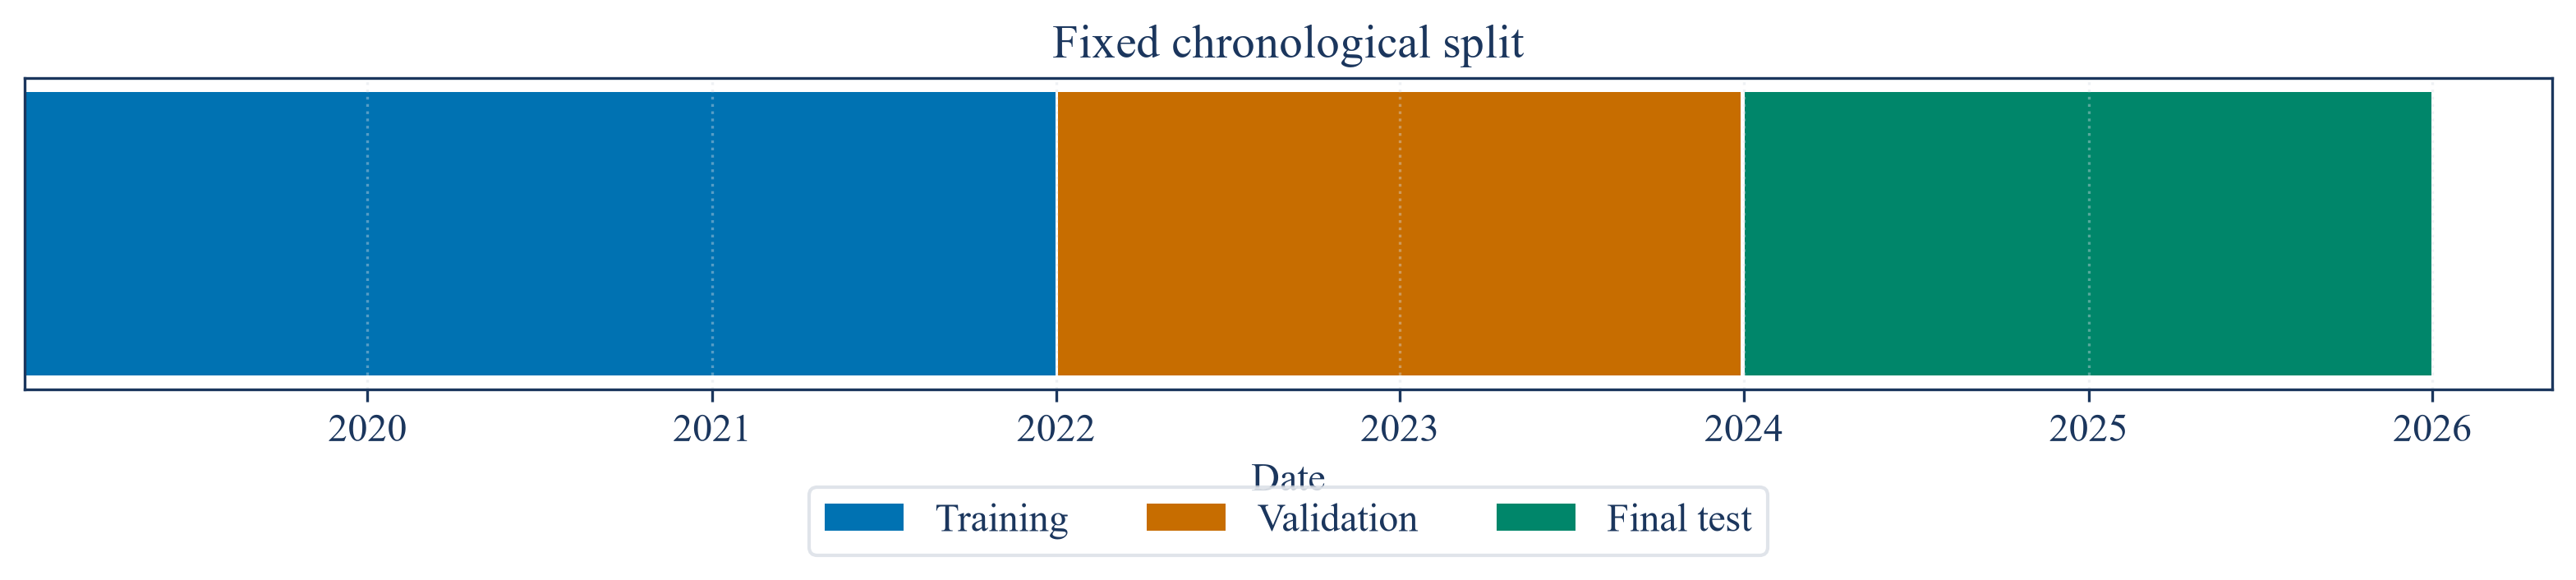

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path
import hashlib
import inspect
import io
import sys
import time
import warnings
import zipfile
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import parallel_config
from IPython.display import Image

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parents[1]

from RiskLabAI.hpc import linear_partitions, nested_partitions, mp_pandas_obj, parallel_run, process_jobs, process_jobs_sequential
from RiskLabAI.core import BARS, BET_SIZERS, CROSS_VALIDATORS, FEATURE_IMPORTANCE, LABELERS, PORTFOLIO_OPTIMIZERS, BaseLabeler, Registry, list_components
from RiskLabAI.controller.bars_initializer import BarsInitializerController
from RiskLabAI.controller.data_structure_controller import BAR_COLUMNS, Controller
from RiskLabAI.optimization.hrp import hrp, inverse_variance_weights

FIGURES = ROOT / "outputs" / "figures" / "32_reproducible_research_study"
TABLES = ROOT / "outputs" / "tables" / "32_reproducible_research_study"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5", "muted": "#5C6670"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def display_float(value):
    if not np.isfinite(value):
        return str(value)
    nearest_integer = round(float(value))
    if np.isclose(value, nearest_integer, atol=1e-12):
        return str(int(nearest_integer))
    if abs(value) < 5e-13:
        return "0"
    return f"{value:.6f}".rstrip("0").rstrip(".")

pd.set_option("display.float_format", display_float)

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True):
    table_frame = frame.copy()
    for column in table_frame.columns:
        if pd.api.types.is_bool_dtype(table_frame[column]):
            table_frame[column] = table_frame[column].map({True: "Yes", False: "No"})
    table_frame.to_csv(TABLES / f"{stem}.csv", index=False, float_format=compact_float_format("%.10f"))
    latex = compact_table_latex(table_frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position="tbp"))
    if fit:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{adjustbox}{max width=\textwidth}" + "\n" + r"\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}" + "\n" + r"\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    latex = latex.replace("nan", "Not available").replace("NaN", "Not available").replace("inf", "No finite value")
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def save_figure(figure, stem):
    figure.savefig(FIGURES / f"{stem}.png", bbox_inches="tight", dpi=300)
    figure.savefig(FIGURES / f"{stem}.pdf", bbox_inches="tight")
    display(Image(filename=str(FIGURES / f"{stem}.png")))
    plt.close(figure)

def load_french_returns():
    data_path = ROOT / "data" / "public" / "ken_french" / "49_Industry_Portfolios_daily_CSV.zip"
    expected_hash = "8F394FE34BEA54D41B9AAFED410425EE8F8E252EDE3C71A7C1CD20BAB83040DE"
    assert data_path.is_file()
    data_hash = hashlib.sha256(data_path.read_bytes()).hexdigest().upper()
    assert data_hash == expected_hash
    with zipfile.ZipFile(data_path) as archive:
        archive_name = archive.namelist()[0]
        public_lines = archive.read(archive_name).decode("latin1").splitlines()
    header_row = next(index for index, line in enumerate(public_lines) if line.startswith(",Agric"))
    end_row = next(index for index in range(header_row + 1, len(public_lines)) if not public_lines[index].strip())
    raw_frame = pd.read_csv(io.StringIO("\n".join(public_lines[header_row:end_row])))
    raw_frame = raw_frame.rename(columns={raw_frame.columns[0]: "Date"})
    raw_frame["Date"] = pd.to_datetime(raw_frame["Date"].astype(str), format="%Y%m%d")
    returns = raw_frame.set_index("Date").replace([-99.99, -999.0], np.nan) / 100.0
    returns = returns.loc["2019-01-01":"2025-12-31"].dropna().copy()
    return returns, data_path, data_hash

def load_binance_rows(record_limit=5000):
    data_path = ROOT / "data" / "public" / "binance" / "BTCUSDT-1m-2021-01.zip"
    expected_hash = "9364A063EFA0604D5B9D2536FB68F922DA5AFA3D8F94A26A527471A1E2F87801"
    assert data_path.is_file()
    data_hash = hashlib.sha256(data_path.read_bytes()).hexdigest().upper()
    assert data_hash == expected_hash
    columns = ["Open time", "Open", "High", "Low", "Close", "Volume", "Close time", "Quote volume", "Trades", "Buyer base volume", "Buyer quote volume", "Unused"]
    raw_frame = pd.read_csv(data_path, compression="zip", header=None, names=columns, nrows=record_limit)
    times = pd.to_datetime(raw_frame["Open time"], unit="ms", utc=True).dt.tz_convert(None)
    rows = pd.DataFrame({"Date Time": times, "Price": raw_frame["Close"].astype(float), "Volume": raw_frame["Volume"].astype(float)})
    return rows, data_path, data_hash

def annualized_volatility(returns):
    return float(returns.std(ddof=1) * np.sqrt(252.0))

def maximum_drawdown(returns):
    wealth = (1.0 + returns).cumprod()
    drawdown = wealth / wealth.cummax() - 1.0
    return float(drawdown.min())

def portfolio_weights(method, covariance, correlation):
    if method == "Equal weight":
        return pd.Series(1.0 / len(covariance), index=covariance.index)
    if method == "Inverse variance":
        return pd.Series(inverse_variance_weights(covariance), index=covariance.index)
    if method == "Hierarchical risk parity":
        return hrp(covariance, correlation).reindex(covariance.index)
    raise KeyError(method)

def portfolio_record(method, weights, returns):
    path = returns @ weights.reindex(returns.columns)
    concentration = float(np.square(weights).sum())
    return {"Method": method, "Observations": len(path), "Annual mean return": float(path.mean() * 252.0), "Annual volatility": annualized_volatility(path), "Return to volatility": float(path.mean() / path.std(ddof=1) * np.sqrt(252.0)), "Maximum drawdown": maximum_drawdown(path), "Largest weight": float(weights.max()), "Weight concentration": concentration, "Effective holdings": float(1.0 / concentration)}

all_returns, french_path, french_hash = load_french_returns()
asset_names = list(all_returns.columns[:16])
study_returns = all_returns[asset_names].copy()
training_returns = study_returns.loc["2019-01-01":"2021-12-31"]
validation_returns = study_returns.loc["2022-01-01":"2023-12-31"]
final_returns = study_returns.loc["2024-01-01":"2025-12-31"]
pretest_returns = study_returns.loc[:"2023-12-31"]
split_table = pd.DataFrame({"Period": ["Training", "Validation", "Final test"], "Start date": [training_returns.index.min().date(), validation_returns.index.min().date(), final_returns.index.min().date()], "End date": [training_returns.index.max().date(), validation_returns.index.max().date(), final_returns.index.max().date()], "Observations": [len(training_returns), len(validation_returns), len(final_returns)], "Use": ["Estimate candidates", "Choose one method", "Evaluate frozen method"]})
data_provenance = pd.DataFrame({"Field": ["Archive", "Provider", "Return type", "Study start", "Study end", "Complete observations", "Selected industries", "Selection rule", "File SHA256"], "Value": [french_path.name, "Kenneth R. French Data Library", "Daily value-weighted return", str(study_returns.index.min().date()), str(study_returns.index.max().date()), len(study_returns), len(asset_names), "First sixteen industries in archive order", french_hash]})
save_table(data_provenance, "final_study_provenance", "Public data and fixed asset selection for the final study.", "tab:chapter30-study-provenance")
save_table(split_table, "chronological_split", "The fixed training, validation, and final test periods.", "tab:chapter30-time-split")
display(data_provenance)
display(split_table)

figure, axis = plt.subplots(figsize=(10.6, 2.7))
colors = [palette["cyan"], palette["amber"], palette["green"]]
for row, color in zip(split_table.itertuples(), colors):
    start = pd.Timestamp(row[2])
    end = pd.Timestamp(row[3])
    axis.barh(0, (end - start).days, left=start, height=0.45, color=color, label=row.Period)
axis.set_yticks([])
axis.set_xlabel("Date")
axis.set_title("Fixed chronological split")
axis.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.25))
axis.grid(True, axis="x", alpha=0.4)
figure.tight_layout()
save_figure(figure, "chronological_split")
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Three Fixed Candidate Methods

Equal weight and inverse variance use the following rules:

$$
w_i^{\mathrm{EW}}=\frac1p,
\qquad
w_i^{\mathrm{IV}}=\frac{1/\Sigma_{ii}}{\sum_{j=1}^{p}1/\Sigma_{jj}}.
$$

Here, $p$ is the number of industries, $w_i^{\mathrm{EW}}$ is the equal weight for industry $i$, $w_i^{\mathrm{IV}}$ is its inverse variance weight, and $\Sigma_{ii}$ is its estimated return variance. Hierarchical risk parity uses a correlation tree, covariance reordering, and recursive allocation instead of this closed form.

,Industry,Equal weight,Hierarchical risk parity,Inverse variance
0,Agric,0.0625,0.037487,0.036308
1,Food,0.0625,0.110523,0.114307
2,Soda,0.0625,0.075146,0.077718
3,Beer,0.0625,0.070228,0.078438
4,Smoke,0.0625,0.090845,0.061083
5,Toys,0.0625,0.035238,0.026788
6,Fun,0.0625,0.058139,0.044197
7,Books,0.0625,0.055534,0.053788
8,Hshld,0.0625,0.08671,0.096847
9,Clths,0.0625,0.039507,0.045866


,Method,Weight sum,Smallest weight,Largest weight,Weight concentration,Effective holdings,Training annual volatility
0,Equal weight,1,0.0625,0.0625,0.0625,16,0.214478
1,Hierarchical risk parity,1,0.030006,0.110523,0.071156,14.053552,0.200792
2,Inverse variance,1,0.020175,0.114307,0.07303,13.69299,0.199629


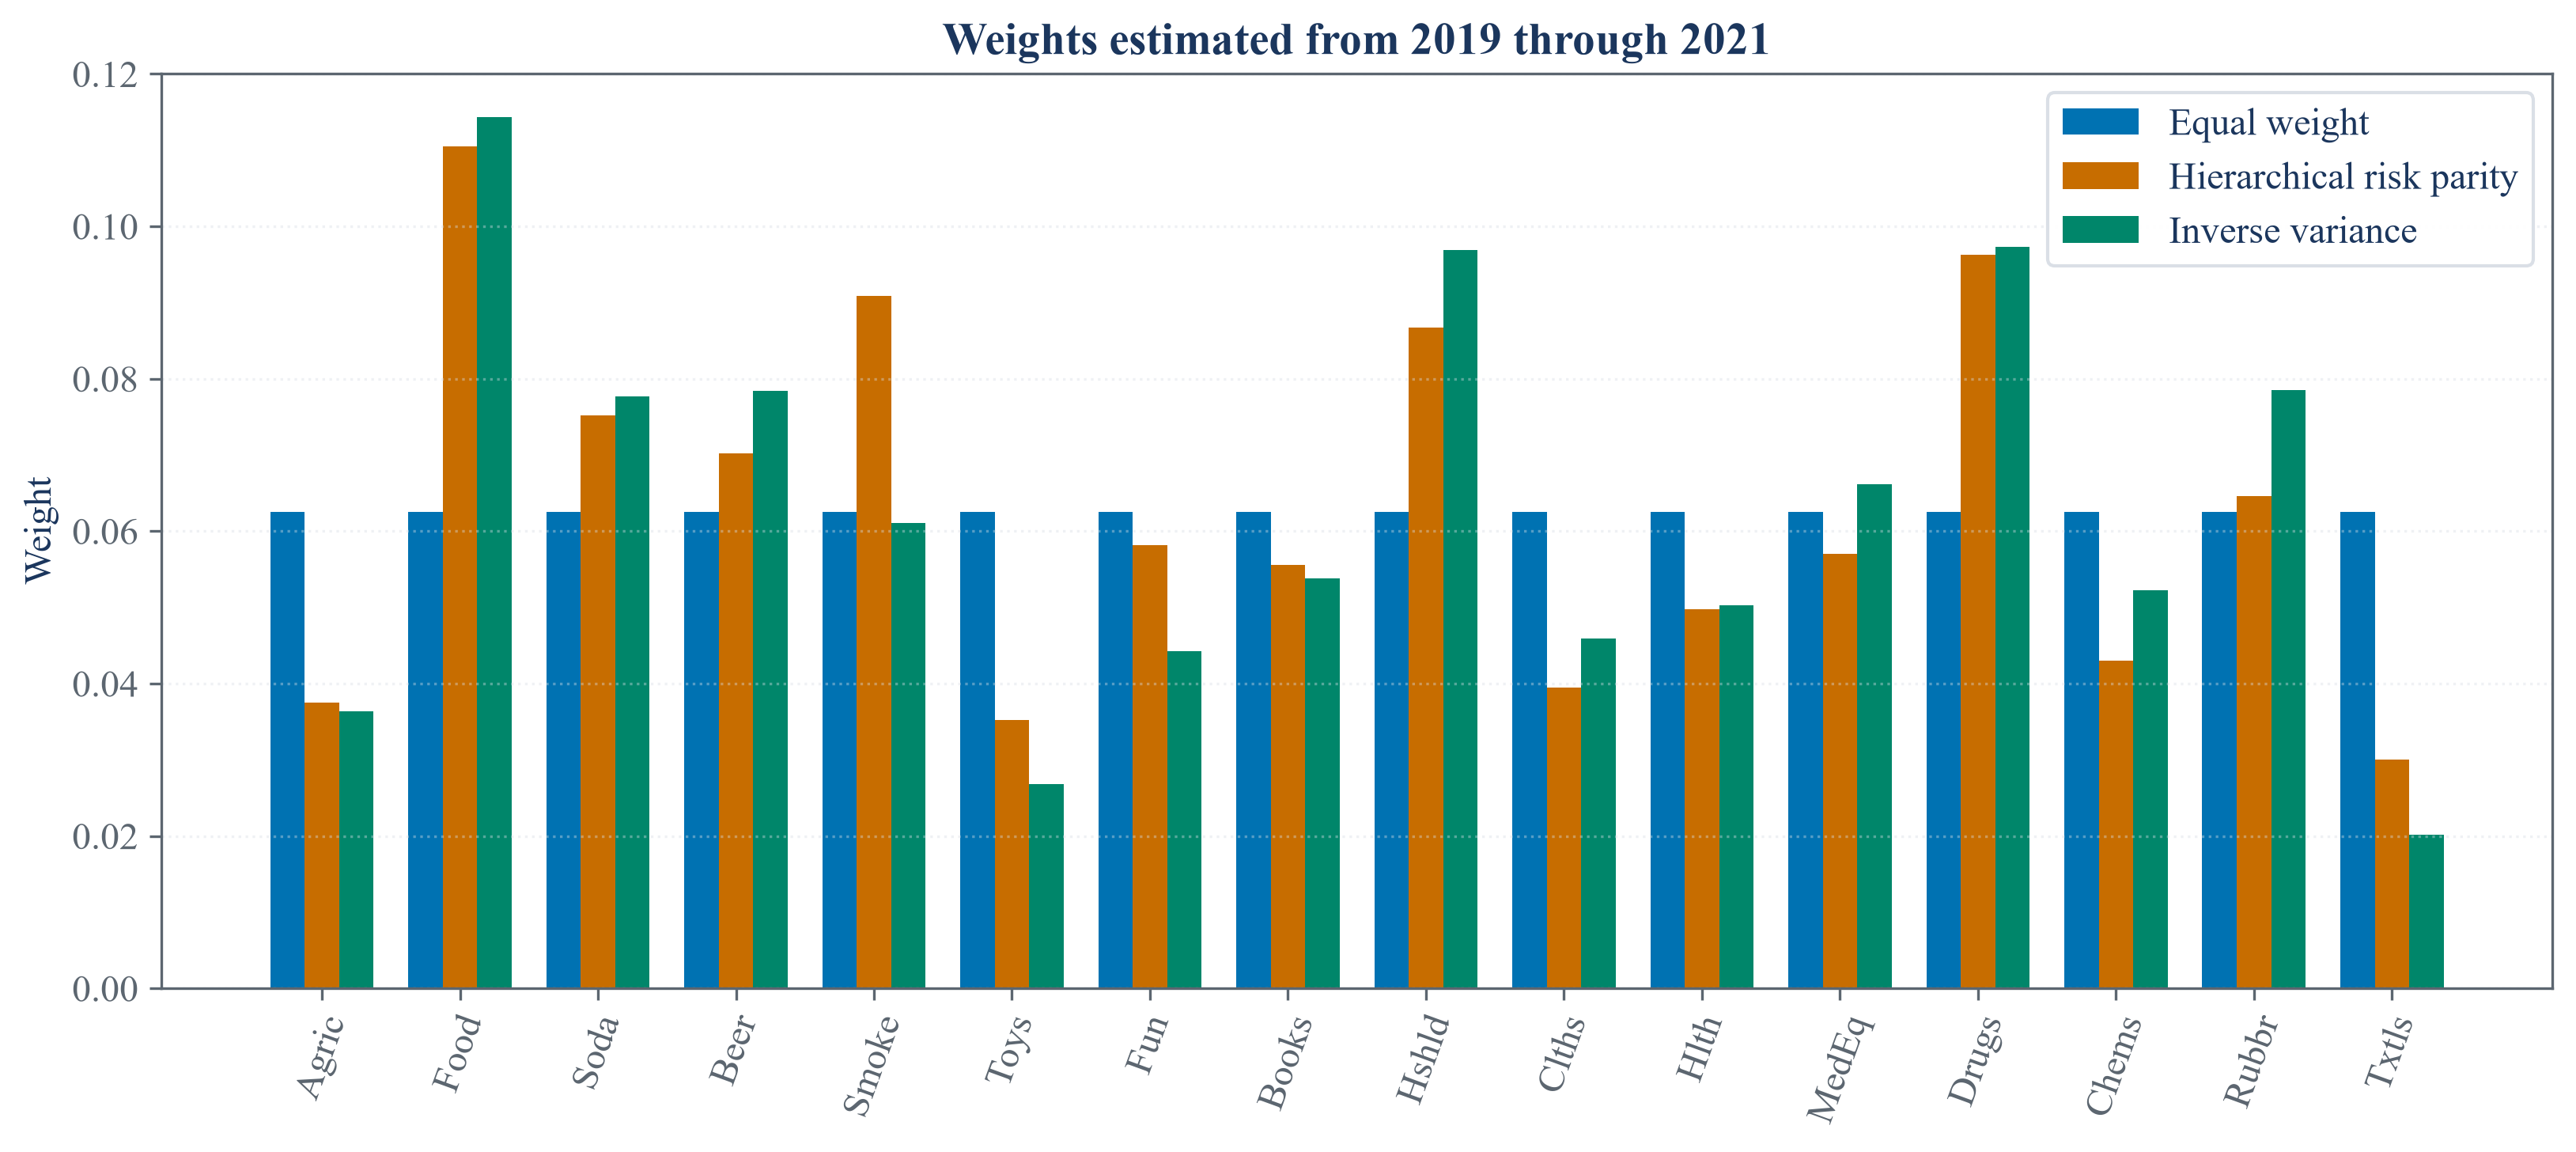

In [2]:
methods = ["Equal weight", "Hierarchical risk parity", "Inverse variance"]
training_covariance = training_returns.cov() * 252.0
training_correlation = training_returns.corr()
training_weights = {method: portfolio_weights(method, training_covariance, training_correlation) for method in methods}
training_weight_table = pd.DataFrame({"Industry": asset_names, **{method: training_weights[method].reindex(asset_names).to_numpy() for method in methods}})
training_diagnostics = pd.DataFrame([{"Method": method, "Weight sum": weights.sum(), "Smallest weight": weights.min(), "Largest weight": weights.max(), "Weight concentration": np.square(weights).sum(), "Effective holdings": 1.0 / np.square(weights).sum(), "Training annual volatility": np.sqrt(float(weights @ training_covariance @ weights))} for method, weights in training_weights.items()])
save_table(training_weight_table, "training_candidate_weights", "Candidate portfolio weights estimated from the training period.", "tab:chapter30-training-weights")
save_table(training_diagnostics, "training_candidate_diagnostics", "Weight and risk checks for the three training estimates.", "tab:chapter30-training-diagnostics")
display(training_weight_table)
display(training_diagnostics)

figure, axis = plt.subplots(figsize=(11.0, 5.0))
positions = np.arange(len(asset_names))
width = 0.25
method_colors = {"Equal weight": palette["cyan"], "Hierarchical risk parity": palette["amber"], "Inverse variance": palette["green"]}
for offset, method in enumerate(methods):
    axis.bar(positions + (offset - 1) * width, training_weights[method].reindex(asset_names), width=width, color=method_colors[method], label=method)
axis.set_xticks(positions)
axis.set_xticklabels(asset_names, rotation=70)
axis.set_ylabel("Weight")
axis.set_title("Weights estimated from 2019 through 2021")
axis.legend()
axis.grid(True, axis="y", alpha=0.4)
figure.tight_layout()
save_figure(figure, "training_candidate_weights")

## Choosing on the Validation Period

The method is chosen by the smallest validation volatility, with alphabetical order used only for an exact tie:

$$
\widehat m=\arg\min_{m\in\mathcal M}^{\mathrm{alphabetical\ tie}}\sqrt{252}\,s\!\left(R_{\mathrm{val}}w_m^{\mathrm{train}}\right).
$$

Here, $\mathcal M$ is the fixed set of three methods, $w_m^{\mathrm{train}}$ is method $m$'s weight vector estimated from training data, $R_{\mathrm{val}}$ is the validation return matrix, $s(\cdot)$ is sample standard deviation, and $\widehat m$ is the selected method.

,Method,Observations,Annual mean return,Annual volatility,Return to volatility,Maximum drawdown,Largest weight,Weight concentration,Effective holdings
0,Inverse variance,501,-0.016671,0.16547,-0.10075,-0.210646,0.114307,0.07303,13.69299
1,Hierarchical risk parity,501,-0.017097,0.165962,-0.103016,-0.214513,0.110523,0.071156,14.053552
2,Equal weight,501,-0.034619,0.183369,-0.188792,-0.250805,0.0625,0.0625,16


,Decision item,Recorded value
0,Fixed candidates,3
1,Selection measure,Smallest validation annual volatility
2,Tie rule,Alphabetical method name
3,Selected method,Inverse variance
4,Final period used for choice,No


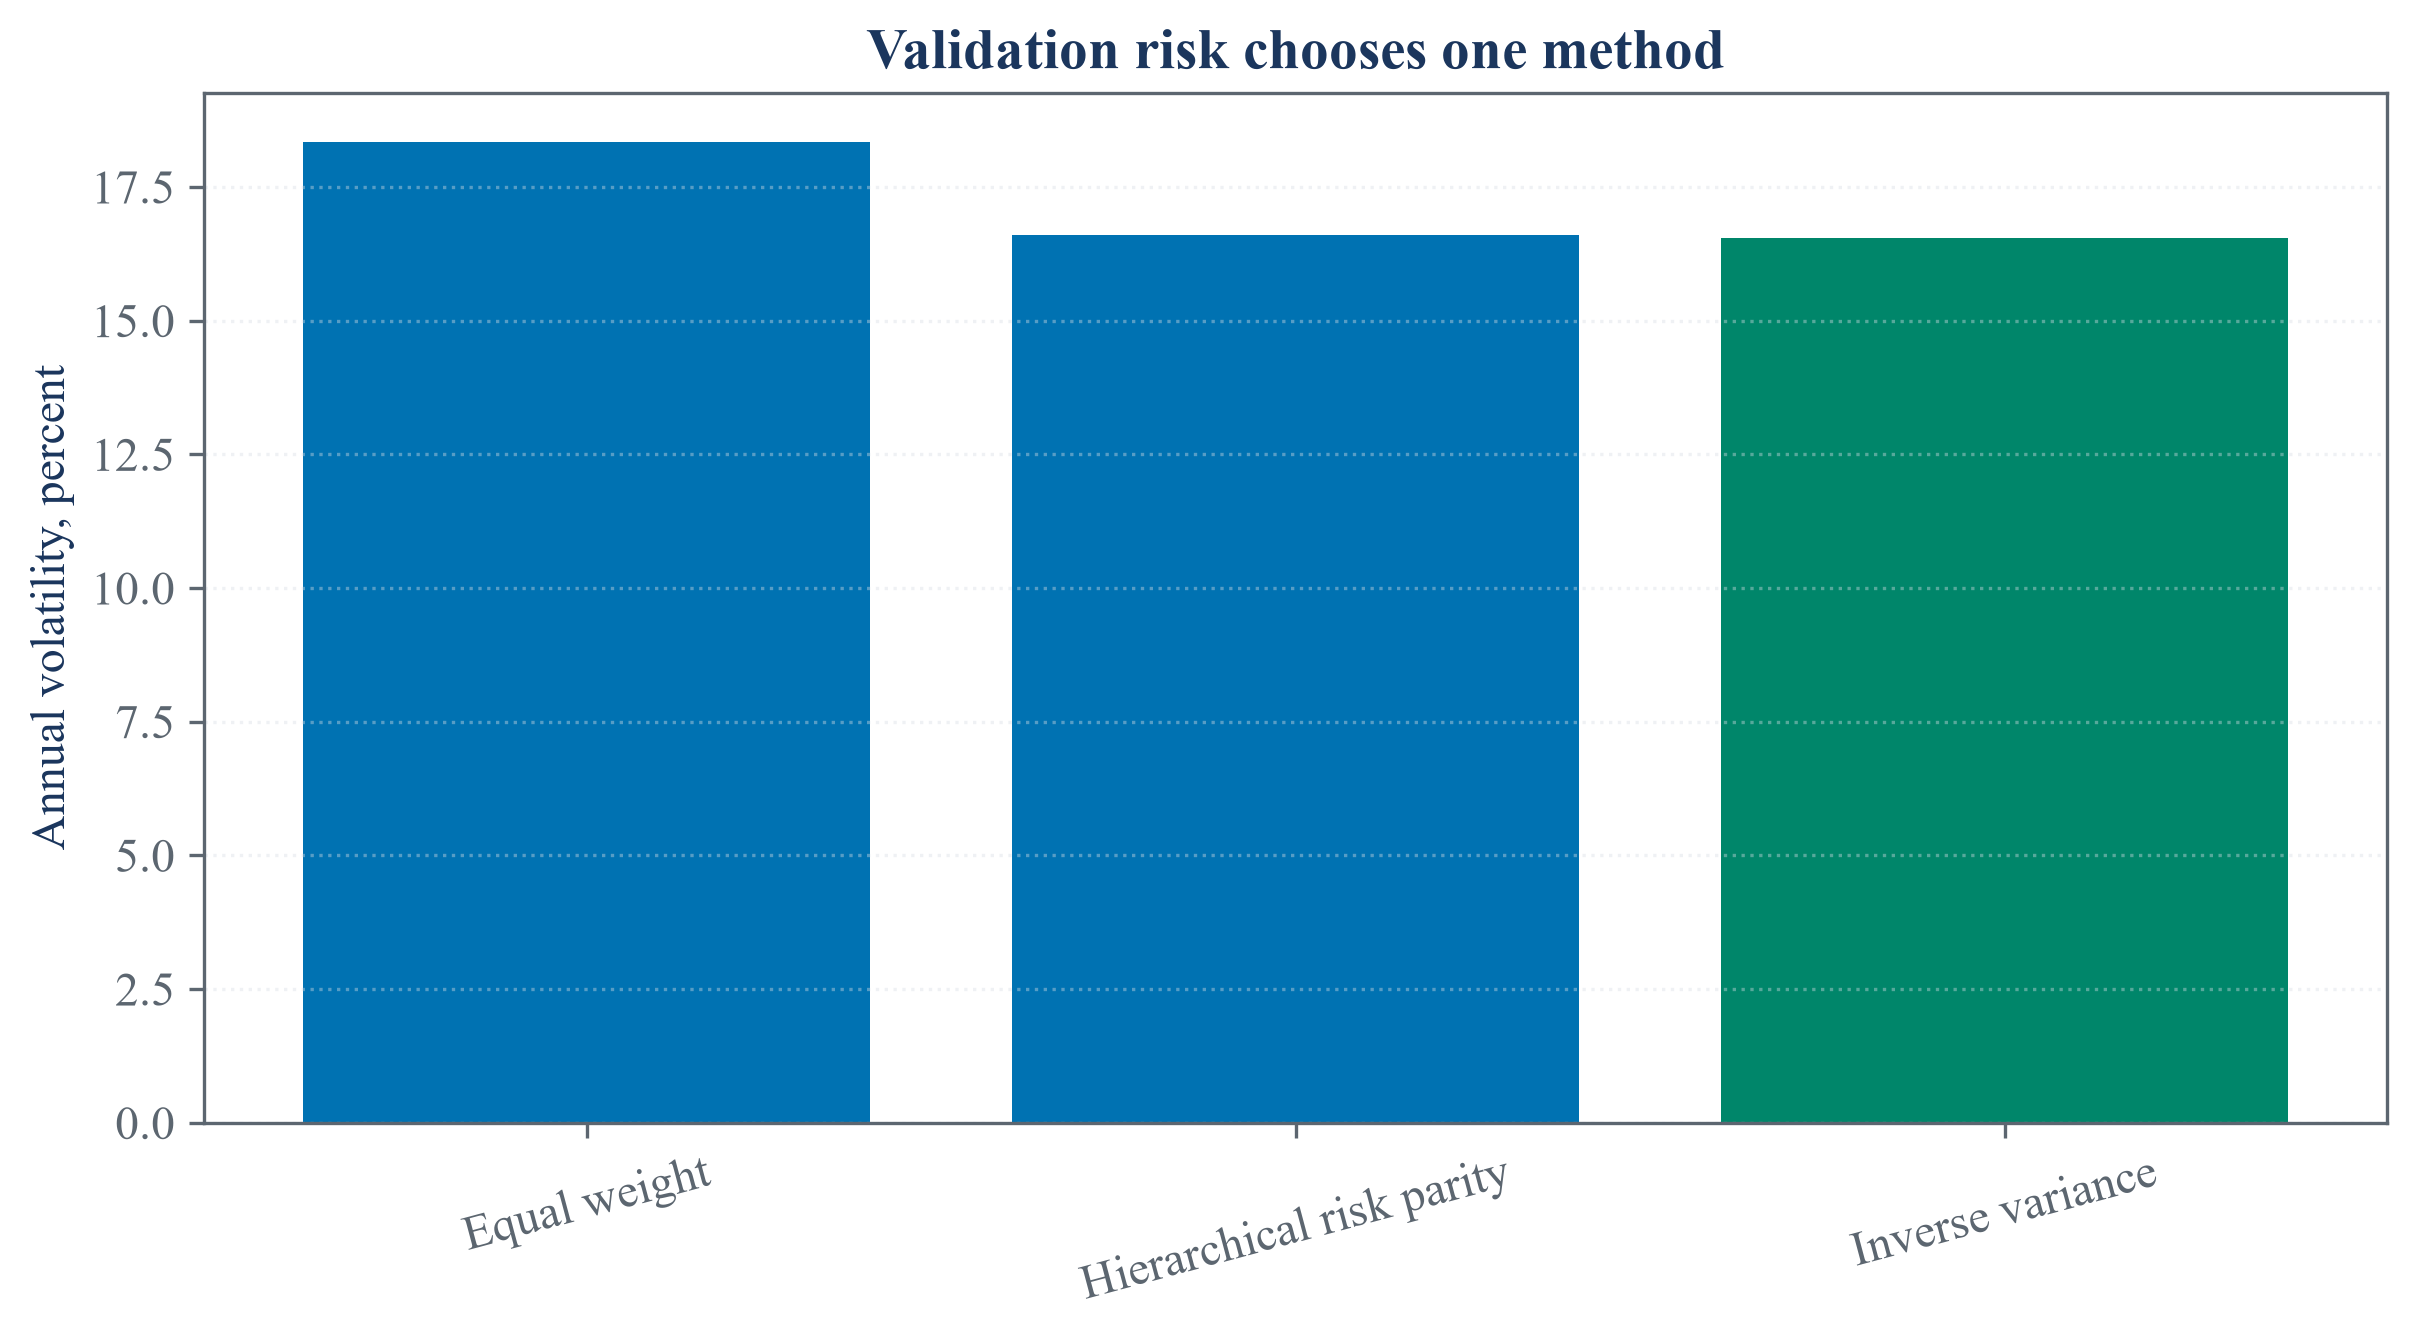

In [3]:
validation_records = [portfolio_record(method, training_weights[method], validation_returns) for method in methods]
validation_table = pd.DataFrame(validation_records).sort_values(["Annual volatility", "Method"]).reset_index(drop=True)
selected_method = validation_table.iloc[0]["Method"]
selection_table = pd.DataFrame({"Decision item": ["Fixed candidates", "Selection measure", "Tie rule", "Selected method", "Final period used for choice"], "Recorded value": [len(methods), "Smallest validation annual volatility", "Alphabetical method name", selected_method, "No"]})
save_table(validation_table, "validation_method_comparison", "Validation results for the three methods fixed before comparison.", "tab:chapter30-validation-comparison")
save_table(selection_table, "portfolio_selection_record", "The fixed rule and its observed selection.", "tab:chapter30-selection-record")
display(validation_table)
display(selection_table)

figure, axis = plt.subplots(figsize=(8.2, 4.6))
ordered = validation_table.sort_values("Method")
colors = [palette["green"] if method == selected_method else palette["cyan"] for method in ordered["Method"]]
axis.bar(ordered["Method"], ordered["Annual volatility"] * 100.0, color=colors)
axis.set_ylabel("Annual volatility, percent")
axis.set_title("Validation risk chooses one method")
axis.tick_params(axis="x", rotation=15)
axis.grid(True, axis="y", alpha=0.4)
figure.tight_layout()
save_figure(figure, "validation_risk")

## Refit Before the Final Test

Final period variance and weight concentration are measured as:

$$
\widehat\sigma_m^2=w_m^{\mathsf T}\widehat\Sigma_{\mathrm{test}}w_m,
\qquad H_m=\sum_{i=1}^{p}w_{m,i}^2,
\qquad N_{\mathrm{eff},m}=\frac1{H_m}.
$$

Here, $w_m$ is method $m$'s weight vector refitted with all observations through 2023, $\widehat\Sigma_{\mathrm{test}}$ is the final period covariance matrix, $H_m$ is weight concentration, and $N_{\mathrm{eff},m}$ is the effective number of equally weighted holdings.

,Industry,Equal weight,Hierarchical risk parity,Inverse variance
0,Agric,0.0625,0.042544,0.039695
1,Food,0.0625,0.103594,0.119751
2,Soda,0.0625,0.10704,0.08507
3,Beer,0.0625,0.093474,0.087214
4,Smoke,0.0625,0.084577,0.067217
5,Toys,0.0625,0.03072,0.02524
6,Fun,0.0625,0.040748,0.033479
7,Books,0.0625,0.055314,0.051695
8,Hshld,0.0625,0.083332,0.096328
9,Clths,0.0625,0.038616,0.038779


,Method,Observations,Annual mean return,Annual volatility,Return to volatility,Maximum drawdown,Largest weight,Weight concentration,Effective holdings
0,Hierarchical risk parity,502,0.080572,0.120147,0.670616,-0.11703,0.109658,0.075452,13.253372
1,Inverse variance,502,0.069786,0.121613,0.573836,-0.126689,0.119751,0.074939,13.344209
2,Equal weight,502,0.082283,0.134535,0.611606,-0.149905,0.0625,0.0625,16


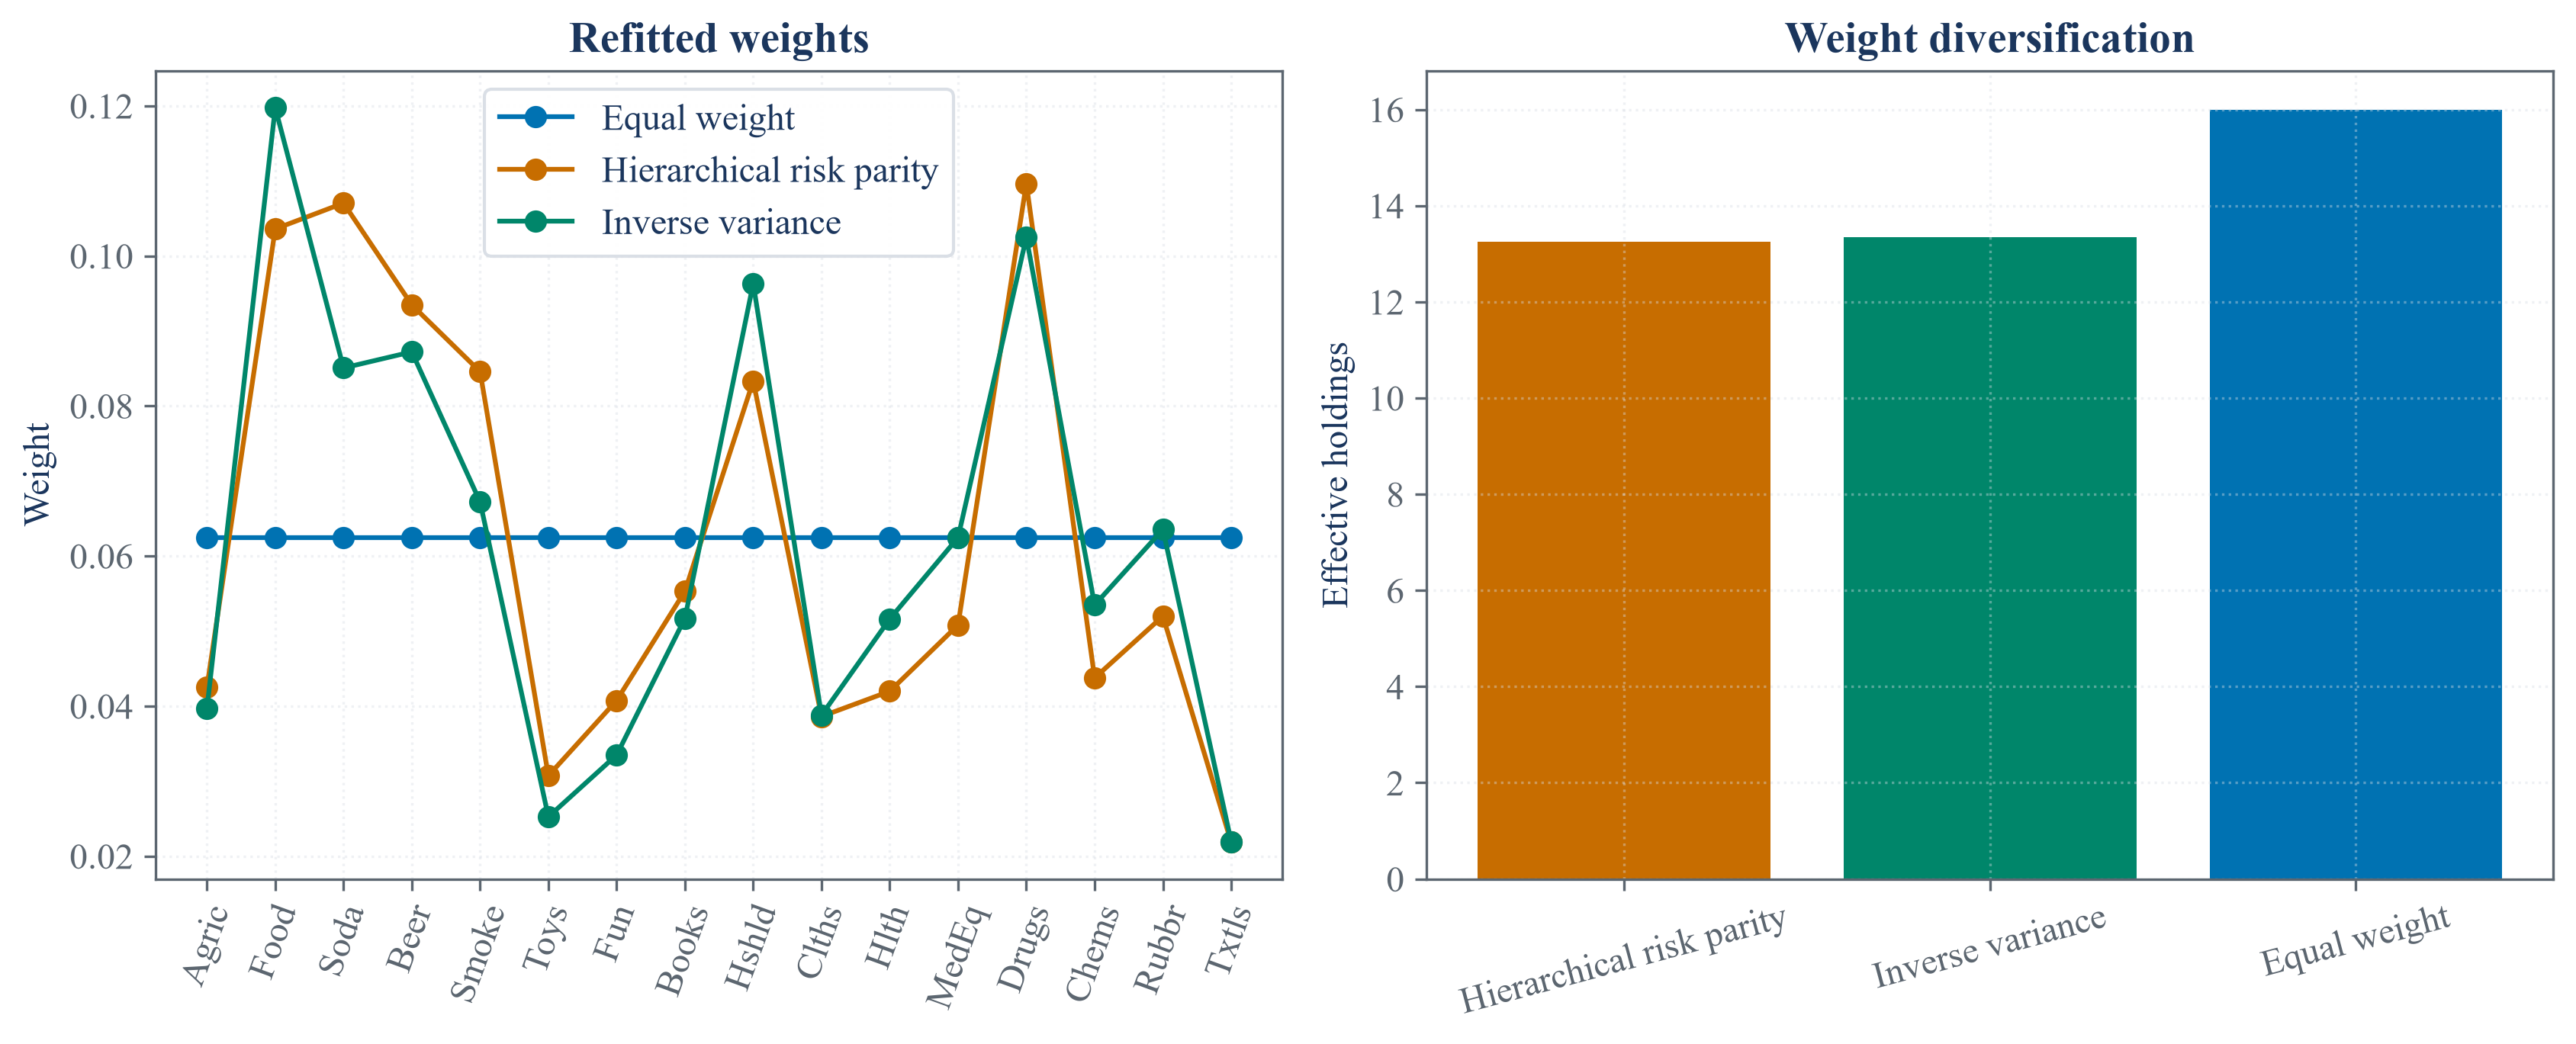

In [4]:
pretest_covariance = pretest_returns.cov() * 252.0
pretest_correlation = pretest_returns.corr()
refitted_weights = {method: portfolio_weights(method, pretest_covariance, pretest_correlation) for method in methods}
refitted_weight_table = pd.DataFrame({"Industry": asset_names, **{method: refitted_weights[method].reindex(asset_names).to_numpy() for method in methods}})
final_table = pd.DataFrame([portfolio_record(method, refitted_weights[method], final_returns) for method in methods]).sort_values(["Annual volatility", "Method"]).reset_index(drop=True)
final_best_method = final_table.iloc[0]["Method"]
selected_final_row = final_table.loc[final_table["Method"] == selected_method].iloc[0]
save_table(refitted_weight_table, "refitted_candidate_weights", "Candidate weights refitted with all observations through 2023.", "tab:chapter30-refitted-weights")
save_table(final_table, "final_period_comparison", "Final period results for the frozen candidate set.", "tab:chapter30-final-comparison")
display(refitted_weight_table)
display(final_table)

figure, axes = plt.subplots(1, 2, figsize=(11.4, 4.7))
for method in methods:
    axes[0].plot(asset_names, refitted_weights[method].reindex(asset_names), marker="o", linewidth=1.5, color=method_colors[method], label=method)
axes[0].set_ylabel("Weight")
axes[0].set_title("Refitted weights")
axes[0].tick_params(axis="x", rotation=70)
axes[0].legend()
axes[1].bar(final_table["Method"], final_table["Effective holdings"], color=[method_colors[method] for method in final_table["Method"]])
axes[1].set_ylabel("Effective holdings")
axes[1].set_title("Weight diversification")
axes[1].tick_params(axis="x", rotation=15)
for axis in axes:
    axis.grid(True, alpha=0.4)
figure.tight_layout()
save_figure(figure, "refitted_weights_and_concentration")

## Comparing final equity paths

A cumulative path and its drawdown are calculated from daily returns as:

$$
V_t=\prod_{s=1}^{t}(1+r_s),
\qquad D_t=\frac{V_t}{\max_{1\leq u\leq t}V_u}-1.
$$

Here, $r_s$ is a portfolio return on final period day $s$, $V_t$ is cumulative wealth from one unit of initial wealth, and $D_t$ is the percentage distance below the highest wealth observed through day $t$.

,Method,Ending wealth,Worst drawdown,Days below prior peak
0,Equal weight,1.157135,-0.149905,459
1,Hierarchical risk parity,1.157368,-0.11703,459
2,Inverse variance,1.132375,-0.126689,465


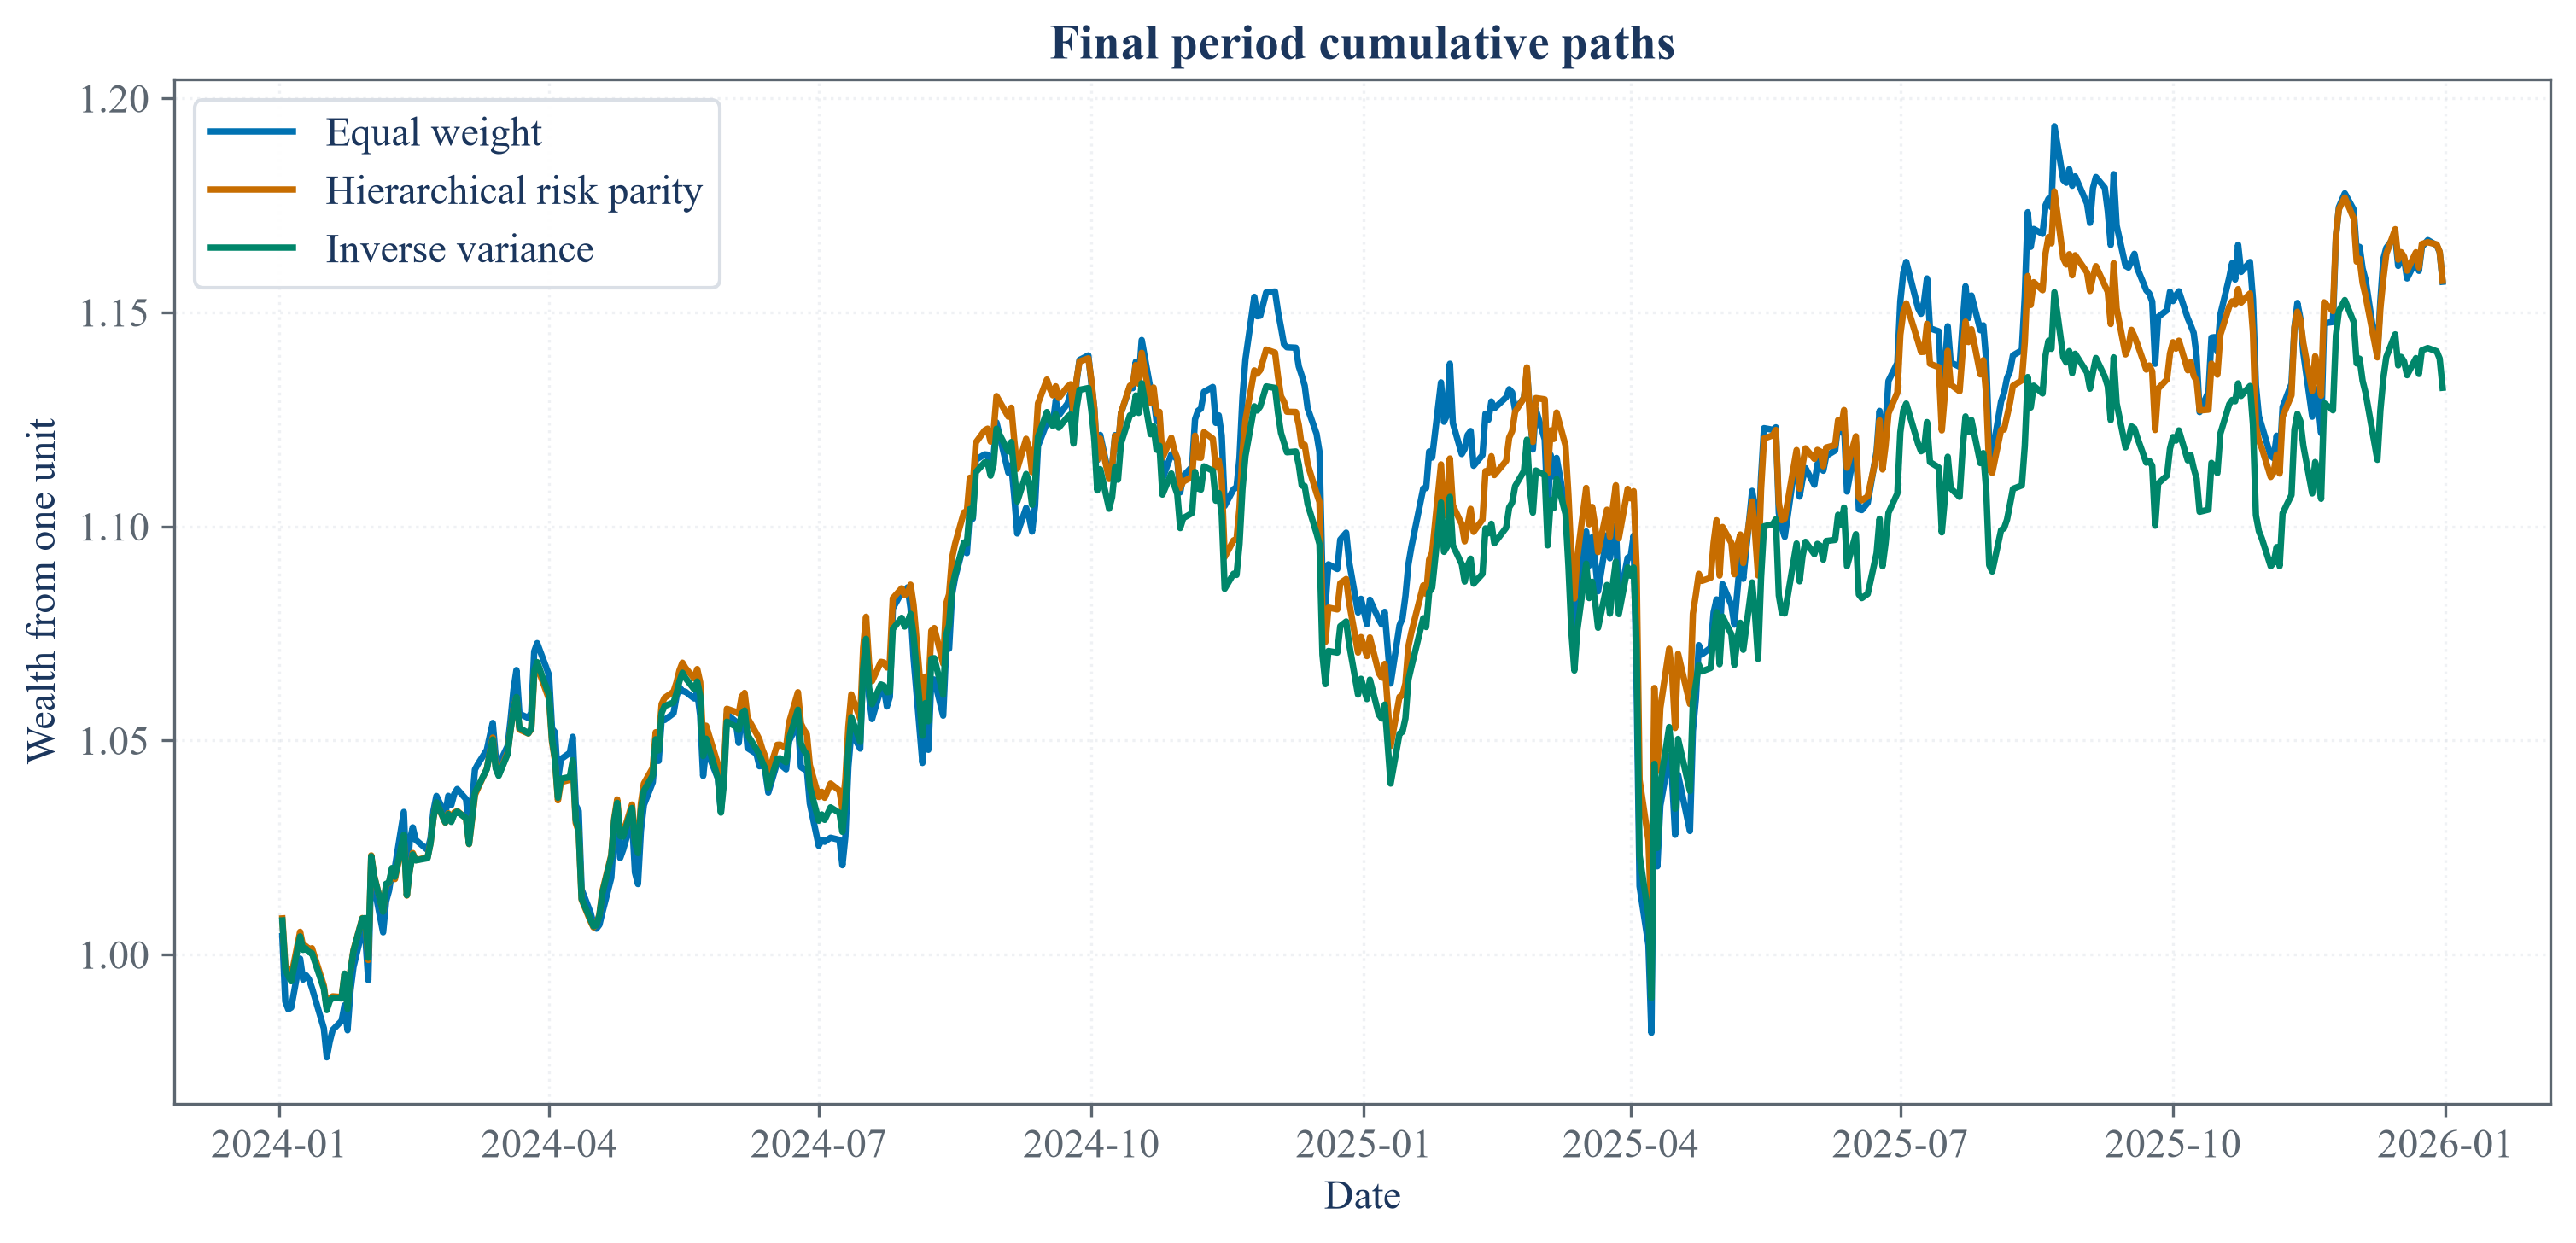

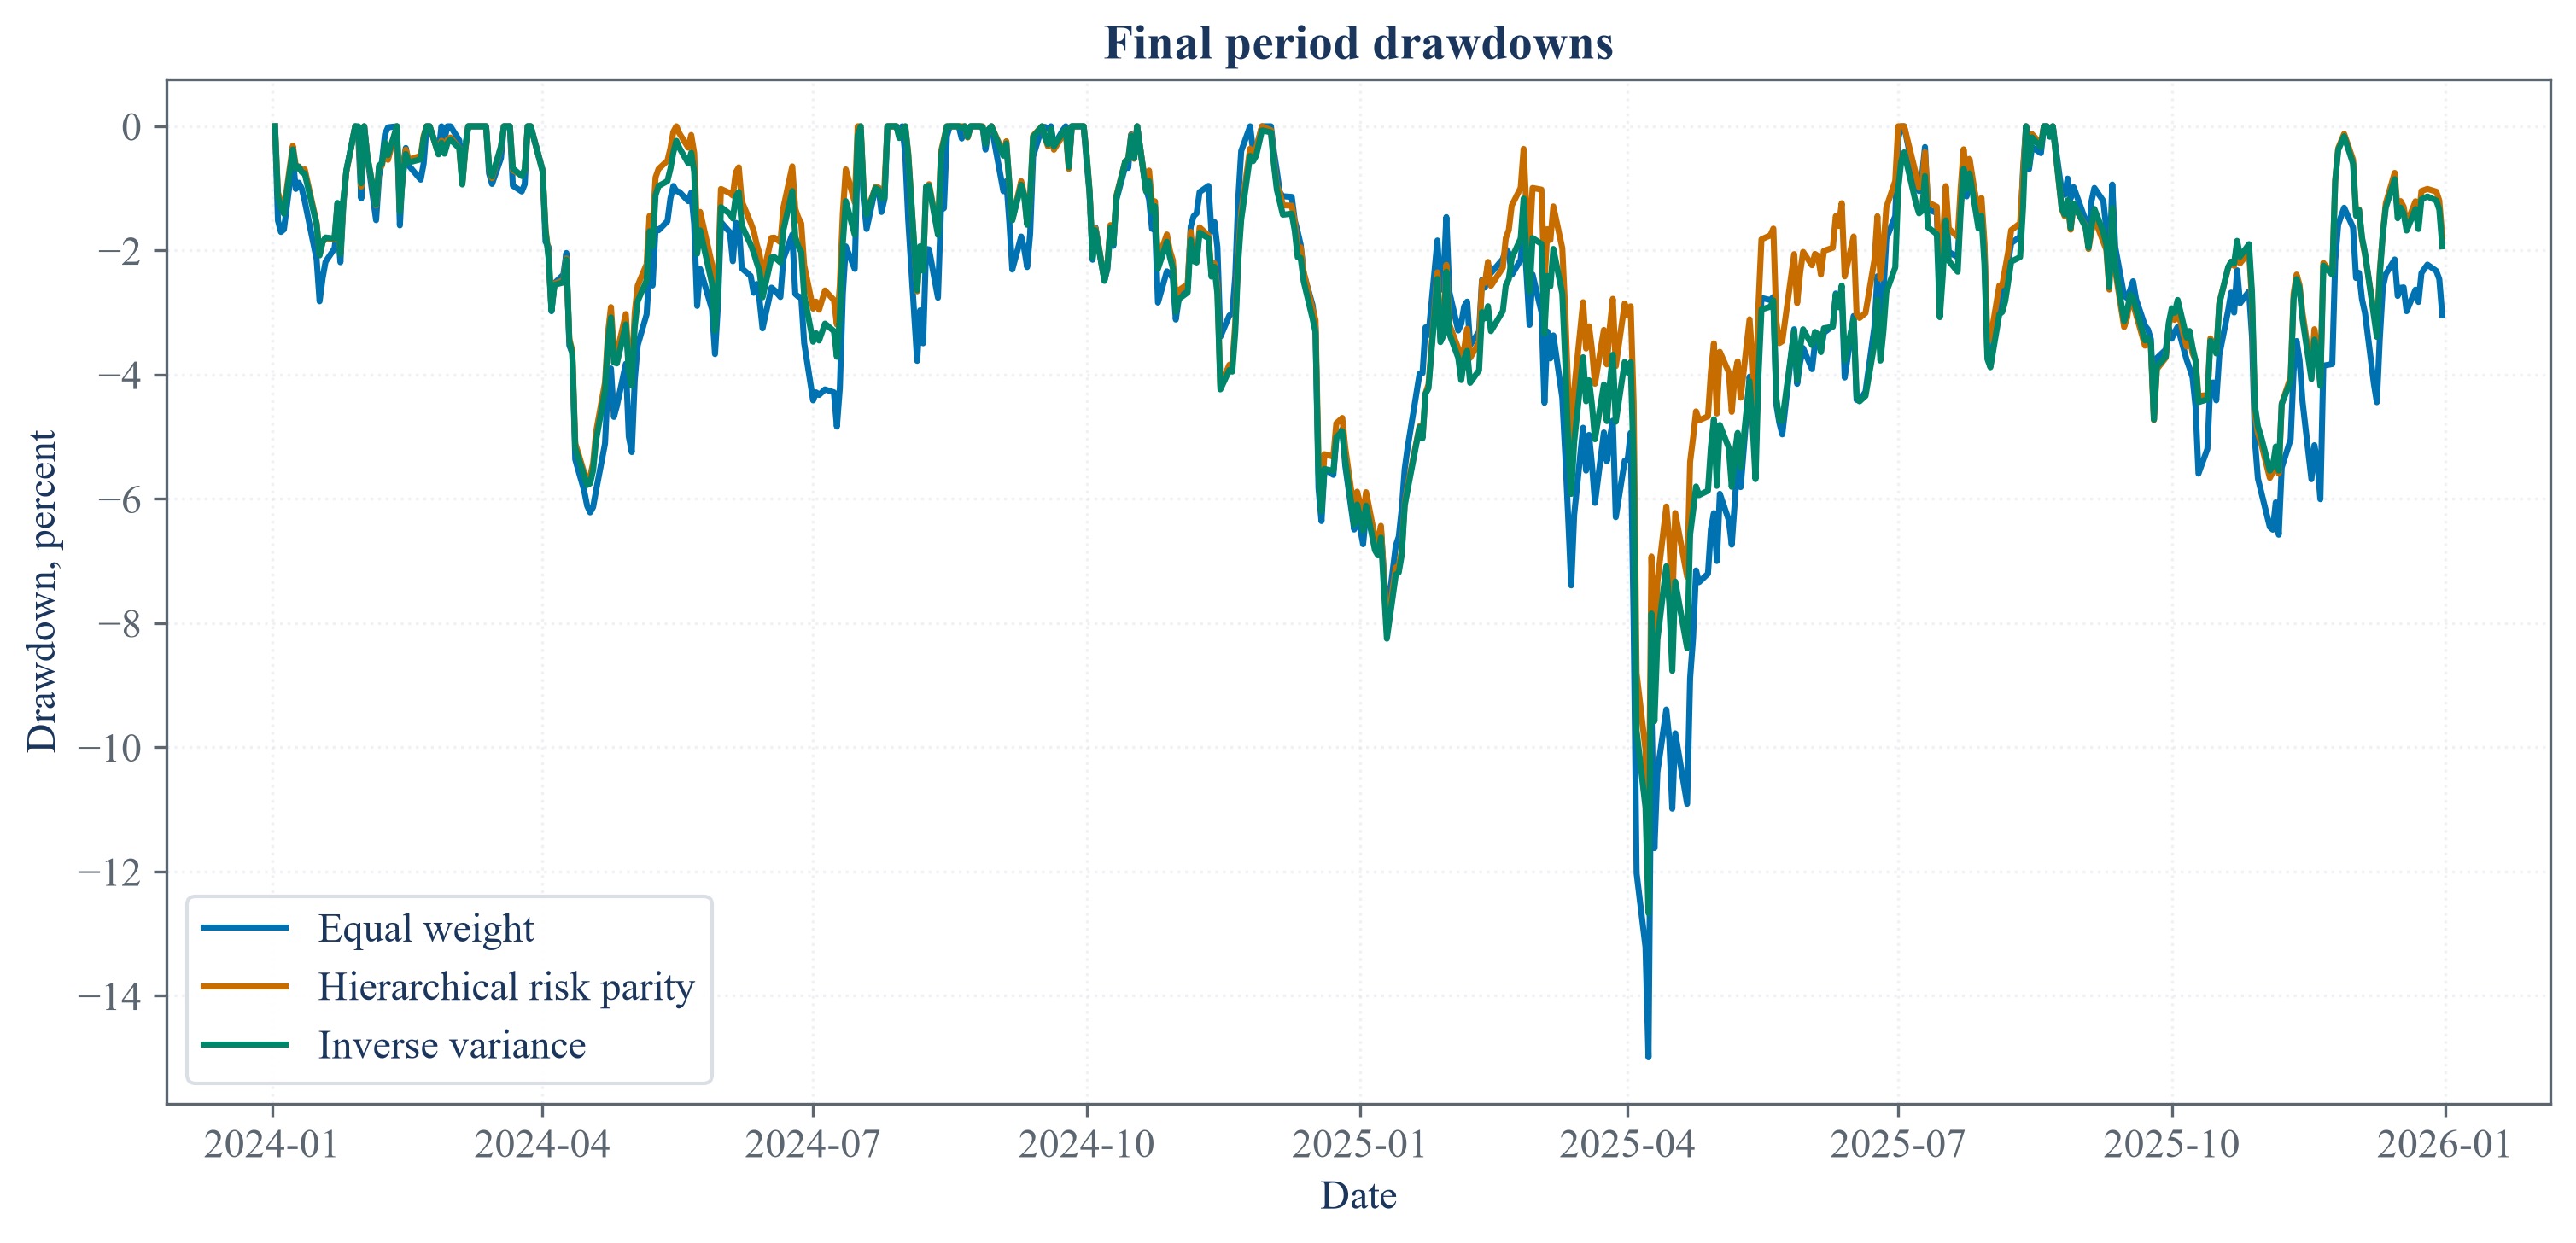

In [5]:
final_paths = pd.DataFrame(index=final_returns.index)
final_drawdowns = pd.DataFrame(index=final_returns.index)
for method in methods:
    daily = final_returns @ refitted_weights[method].reindex(asset_names)
    final_paths[method] = (1.0 + daily).cumprod()
    final_drawdowns[method] = final_paths[method] / final_paths[method].cummax() - 1.0
final_path_summary = pd.DataFrame({"Method": methods, "Ending wealth": [final_paths[method].iloc[-1] for method in methods], "Worst drawdown": [final_drawdowns[method].min() for method in methods], "Days below prior peak": [(final_drawdowns[method] < 0).sum() for method in methods]})
save_table(final_path_summary, "final_path_summary", "Cumulative wealth and drawdown summaries in the final period.", "tab:chapter30-final-path-summary")
display(final_path_summary)

figure, axis = plt.subplots(figsize=(10.2, 5.0))
for method in methods:
    axis.plot(final_paths.index, final_paths[method], color=method_colors[method], linewidth=1.8, label=method)
axis.set_xlabel("Date")
axis.set_ylabel("Wealth from one unit")
axis.set_title("Final period cumulative paths")
axis.legend()
axis.grid(True, alpha=0.4)
figure.tight_layout()
save_figure(figure, "final_cumulative_paths")

figure, axis = plt.subplots(figsize=(10.2, 5.0))
for method in methods:
    axis.plot(final_drawdowns.index, final_drawdowns[method] * 100.0, color=method_colors[method], linewidth=1.7, label=method)
axis.set_xlabel("Date")
axis.set_ylabel("Drawdown, percent")
axis.set_title("Final period drawdowns")
axis.legend()
axis.grid(True, alpha=0.4)
figure.tight_layout()
save_figure(figure, "final_drawdowns")

## Applying the frozen choice to the final period

,Question,Answer
0,Method chosen on validation data,Inverse variance
1,Lowest final period volatility,Hierarchical risk parity
2,Chosen method final volatility,0.121613
3,Lowest final volatility,0.120147
4,Chosen method changed after final test,No


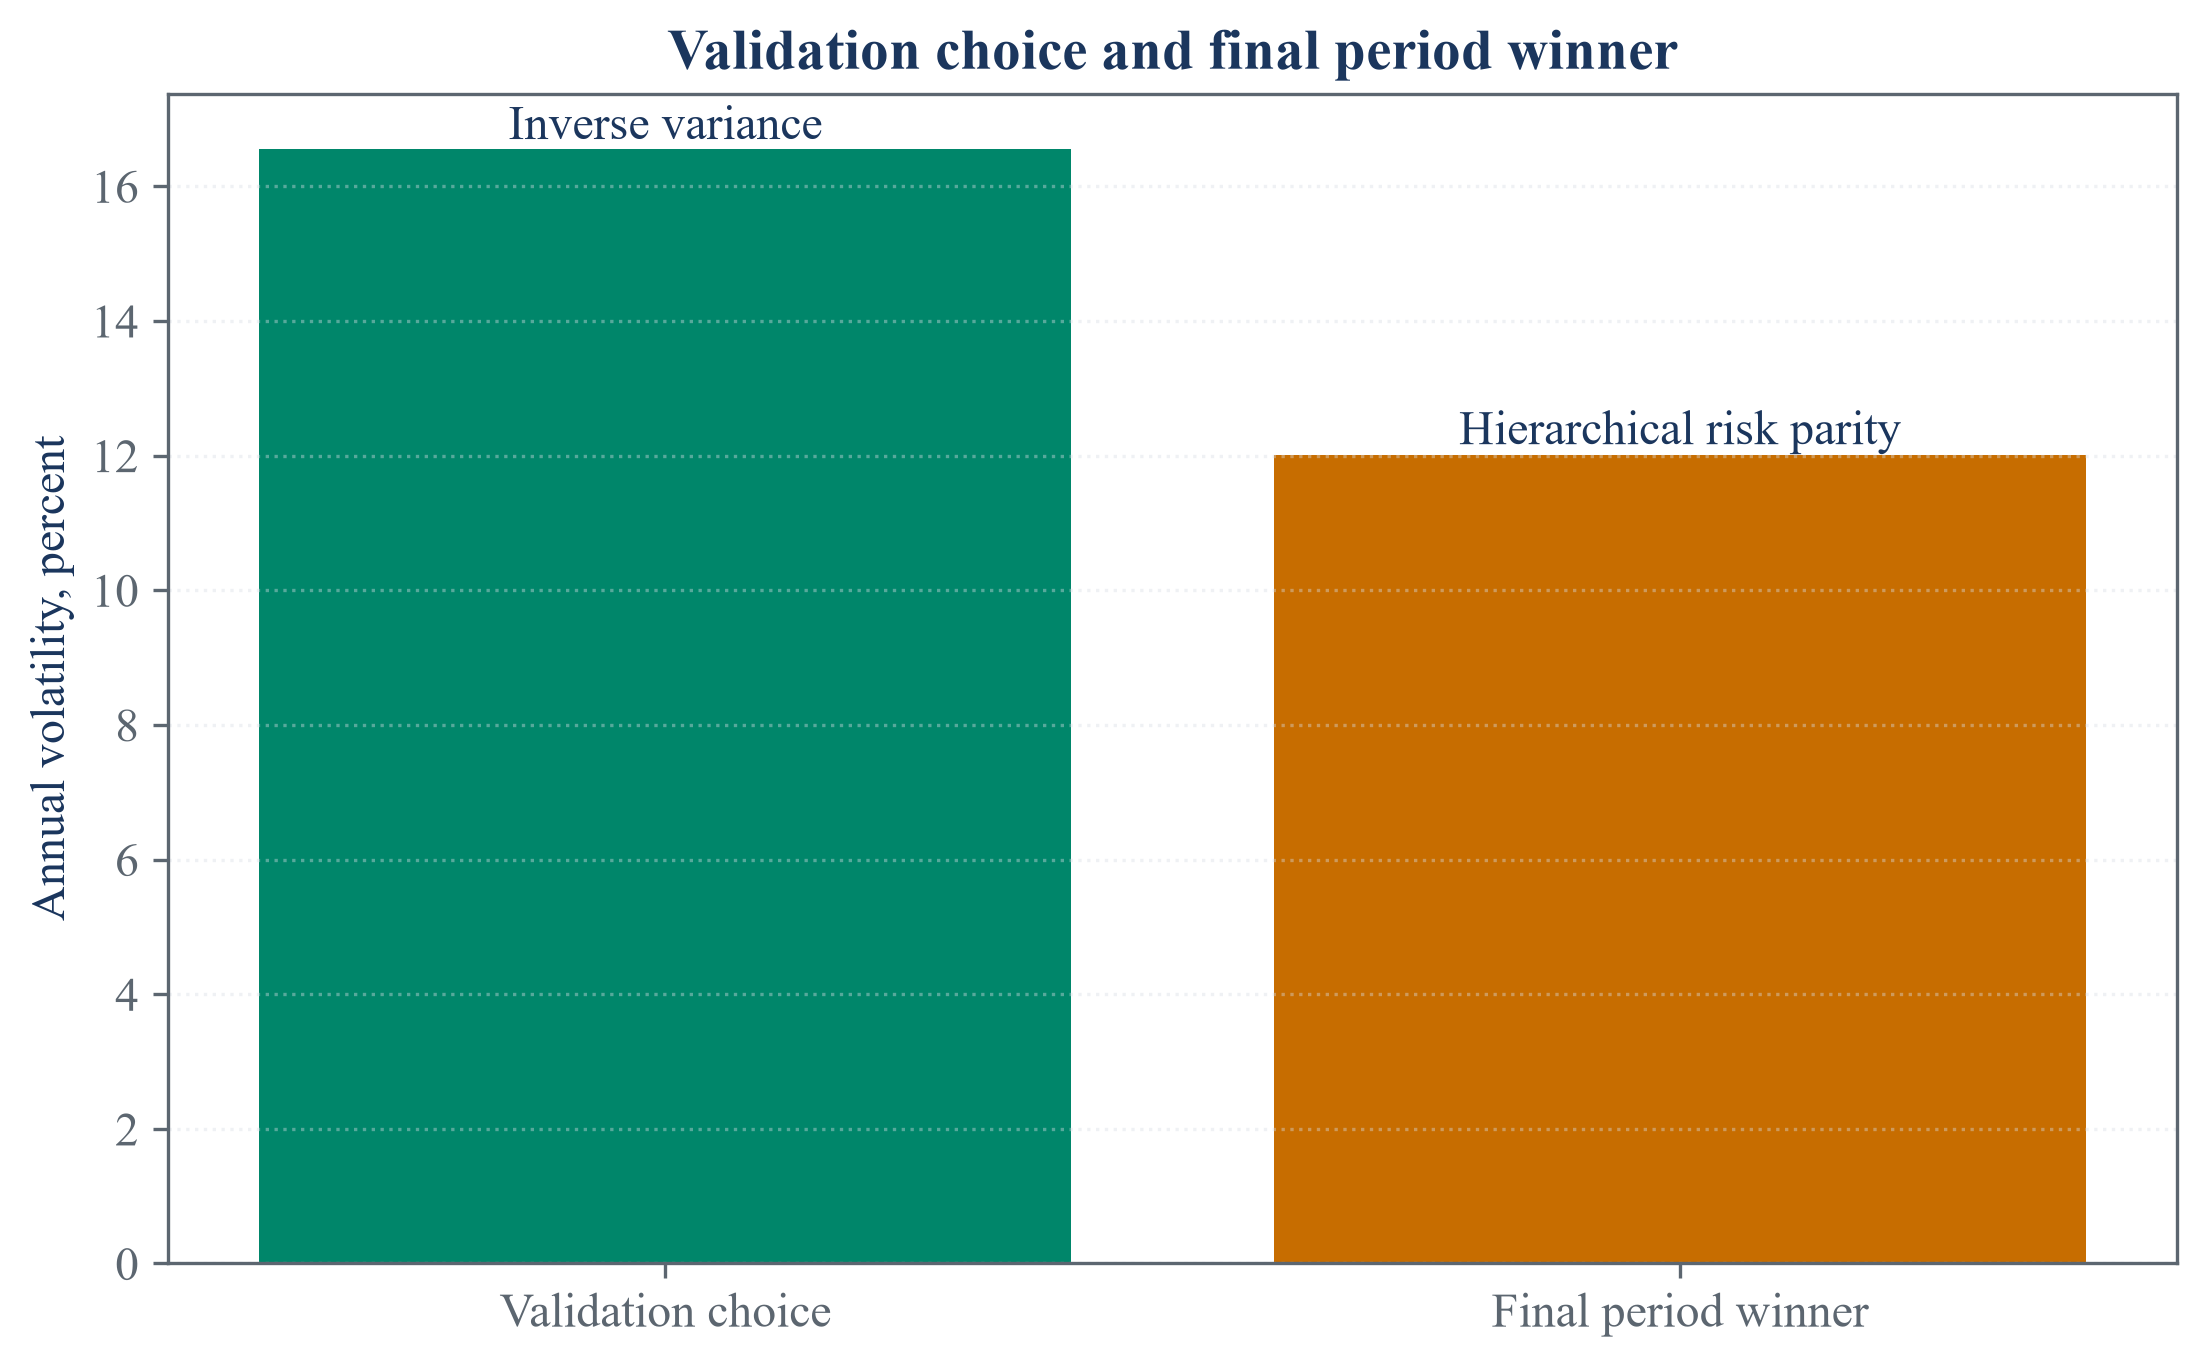

In [6]:
validation_selected_volatility = float(validation_table.loc[validation_table["Method"] == selected_method, "Annual volatility"].iloc[0])
final_best_volatility = float(final_table.iloc[0]["Annual volatility"])
decision_comparison = pd.DataFrame({"Question": ["Method chosen on validation data", "Lowest final period volatility", "Chosen method final volatility", "Lowest final volatility", "Chosen method changed after final test"], "Answer": [selected_method, final_best_method, selected_final_row["Annual volatility"], final_best_volatility, "No"]})
save_table(decision_comparison, "frozen_decision_comparison", "The validation choice is preserved after the final period is observed.", "tab:chapter30-frozen-decision")
display(decision_comparison)

comparison = pd.DataFrame({"Period": ["Validation choice", "Final period winner"], "Annual volatility": [validation_selected_volatility, final_best_volatility], "Method": [selected_method, final_best_method]})
figure, axis = plt.subplots(figsize=(7.5, 4.7))
bars = axis.bar(comparison["Period"], comparison["Annual volatility"] * 100.0, color=[method_colors[selected_method], method_colors[final_best_method]])
for bar, method in zip(bars, comparison["Method"]):
    axis.text(bar.get_x() + bar.get_width() / 2.0, bar.get_height(), method, ha="center", va="bottom", color=palette["text"])
axis.set_ylabel("Annual volatility, percent")
axis.set_title("Validation choice and final period winner")
axis.grid(True, axis="y", alpha=0.4)
figure.tight_layout()
save_figure(figure, "selected_and_final_best")

## Tests

In [7]:
assert len(study_returns) == 1760
assert [len(training_returns), len(validation_returns), len(final_returns)] == [757, 501, 502]
assert len(asset_names) == 16
assert methods == sorted(methods)
assert all(np.isclose(weights.sum(), 1.0) for weights in training_weights.values())
assert all((weights >= 0.0).all() for weights in training_weights.values())
assert all(np.isclose(weights.sum(), 1.0) for weights in refitted_weights.values())
assert all((weights >= 0.0).all() for weights in refitted_weights.values())
assert selected_method == "Inverse variance"
assert final_best_method == "Hierarchical risk parity"
assert np.isclose(validation_selected_volatility, 0.165470, atol=5e-7)
assert np.isclose(float(selected_final_row["Annual volatility"]), 0.121613, atol=5e-7)
assert np.isclose(final_best_volatility, 0.120147, atol=5e-7)
assert decision_comparison.iloc[-1]["Answer"] == "No"
assert final_paths.notna().all().all() and final_drawdowns.notna().all().all()
display(pd.DataFrame({"Test": ["Complete observations", "Fixed split", "Sixteen industries", "Alphabetical method order", "Training weight sums", "Training long only", "Refitted weight sums", "Refitted long only", "Validation choice", "Final period winner", "Validation volatility", "Chosen final volatility", "Lowest final volatility", "Frozen choice", "Finite paths"], "Passed": [True] * 15}))

,Test,Passed
0,Complete observations,True
1,Fixed split,True
2,Sixteen industries,True
3,Alphabetical method order,True
4,Training weight sums,True
5,Training long only,True
6,Refitted weight sums,True
7,Refitted long only,True
8,Validation choice,True
9,Final period winner,True
